# Assignment 5: K-Means Clustering with the Elbow Method

## Problem statement
Cluster a sales-data-like dataset with K-Means, using the elbow method to pick the number
of clusters k.

## Approach
- K-Means partitions points into k clusters by repeatedly assigning each point to its
  nearest cluster center, then recomputing centers as the mean of their assigned points,
  until the assignments stop changing.
- `inertia_` (sum of squared distances from each point to its cluster center) is computed
  for k = 1..10. Inertia always decreases as k grows, so the "elbow" -- the k where the
  curve stops dropping sharply and starts flattening -- is used to pick a good k without
  overfitting to k = 10.
- The elbow is located with a simplified "kneedle" approach: normalize both axes to [0, 1]
  and pick the point furthest from the straight line joining the first and last points of
  the curve (a plain second-derivative check is biased toward the very first drop and picks
  too small a k).
- Features are standardized before clustering because `quantity_ordered` and
  `sales_amount` are on very different numeric scales; without scaling, K-Means' distance
  metric would be dominated by sales_amount alone.

## Dataset
The real Kaggle "Sample Sales Data" (sales_data_sample.csv), 2,823 orders; QUANTITYORDERED
and SALES are used as the two clustering features. Drop `sales_data_sample.csv` next to
this notebook (or in a `data/` subfolder) before running. The file has a couple of
non-UTF-8 bytes in free-text columns (customer/address names), hence `encoding="latin1"`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

NOTEBOOK_DIR = Path.cwd()
DATA_PATH = next(
    (p for p in (NOTEBOOK_DIR / "data" / "sales_data_sample.csv", NOTEBOOK_DIR / "sales_data_sample.csv") if p.exists()),
    NOTEBOOK_DIR / "data" / "sales_data_sample.csv",
)
OUTPUT_PNG = NOTEBOOK_DIR / "elbow_curve.png"

In [2]:
### Helper: locate the elbow (simplified kneedle)

# ELBOW METHOD: compute inertia for k=1..10, pick the "knee" as the k whose
# point is furthest from the straight line joining the first and last points
# of the (k, inertia) curve -- the standard way to locate a knee on a convex,
# decreasing curve (a simplified "kneedle" approach).
def find_elbow(inertias):
    k_values = np.arange(1, len(inertias) + 1)

    # Normalize both axes to [0, 1] so scale doesn't bias the distances.
    k_norm = (k_values - k_values.min()) / (k_values.max() - k_values.min())
    inertia = np.asarray(inertias, dtype=float)
    inertia_norm = (inertia - inertia.min()) / (inertia.max() - inertia.min())

    # Perpendicular distance of each point from the line through the first
    # and last points (both on the normalized curve, which runs (0,1)->(1,0)).
    distances = np.abs(inertia_norm + k_norm - 1) / np.sqrt(2)
    elbow_k = int(k_values[np.argmax(distances)])
    return elbow_k

In [3]:
### Run: load data & scale

# latin1: the file has a few non-UTF-8 bytes in free-text columns we don't use.
raw = pd.read_csv(DATA_PATH, encoding="latin1")
X = raw[["QUANTITYORDERED", "SALES"]].to_numpy(dtype=float)
print(f"Dataset: {len(X)} orders (QUANTITYORDERED vs SALES)")

# QUANTITYORDERED and SALES are on very different scales; without
# scaling, KMeans distances would be dominated by SALES alone.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Dataset: 2823 orders (QUANTITYORDERED vs SALES)


In [4]:
### Compute inertia for k=1..10

k_values = range(1, 11)
inertias = []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

chosen_k = find_elbow(inertias)
print("Inertia per k:")
for k, inertia in zip(k_values, inertias):
    marker = "  <- elbow" if k == chosen_k else ""
    print(f"k={k:<3} inertia={inertia:>14,.1f}{marker}")

Inertia per k:
k=1   inertia=       5,646.0
k=2   inertia=       2,742.1
k=3   inertia=       1,836.8  <- elbow
k=4   inertia=       1,484.9
k=5   inertia=       1,222.3
k=6   inertia=       1,020.4
k=7   inertia=         888.3
k=8   inertia=         783.3
k=9   inertia=         699.0
k=10  inertia=         636.6


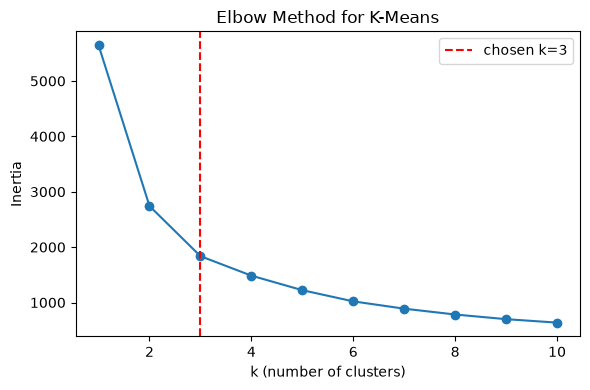

Elbow curve saved to C:\Users\adigo\OneDrive\Desktop\Curricular\LP3\ML\elbow_curve.png


In [5]:
### Plot the elbow curve

plt.figure(figsize=(6, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.axvline(chosen_k, color="red", linestyle="--", label=f"chosen k={chosen_k}")
plt.xlabel("k (number of clusters)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_PNG)
plt.show()
print(f"Elbow curve saved to {OUTPUT_PNG}")

In [6]:
### Final fit at the chosen k

final_km = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
labels = final_km.fit_predict(X_scaled)
centers = scaler.inverse_transform(final_km.cluster_centers_)  # back to original units

print(f"Final K-Means fit with k={chosen_k}:")
print("Cluster centers (QUANTITYORDERED, SALES):")
print(np.round(centers, 1))
print("Cluster sizes:", np.bincount(labels).tolist())

Final K-Means fit with k=3:
Cluster centers (QUANTITYORDERED, SALES):
[[  44.8 6583.5]
 [  26.3 2427.5]
 [  40.9 3407.3]]
Cluster sizes: [520, 1259, 1044]


### Viva prep

**Q: Why does inertia always decrease as k increases, and why not just pick k = 10 (lowest
inertia)?**
A: More clusters can only reduce or keep equal the distance from each point to its nearest
center, so inertia is monotonically non-increasing in k. Always picking the largest k
overfits -- every point could get its own cluster (inertia = 0) but that's useless. The
elbow finds where adding more clusters stops meaningfully helping.

**Q: Why scale features before K-Means but not before a tree-based model?**
A: K-Means clusters based on Euclidean distance, so a feature on a much larger numeric
scale would dominate that distance; tree splits are invariant to the scale of any single
feature.

**Q: What does a high vs low inertia value mean?**
A: Low inertia means points are tightly packed around their cluster centers (good fit for
that k); high inertia means points are spread far from their assigned centers.

**Q: How is the elbow point actually chosen in this script, and why not a simple
second-derivative check?**
A: By normalizing the (k, inertia) curve to [0, 1] on both axes and picking the point with
the largest perpendicular distance from the line joining its first and last points. A plain
second-derivative check is biased toward the very first, largest drop (e.g. k=1 to k=2) and
can miss the true knee further along the curve.